Plate scale calc walk-through with HD189340 for VAMPIRES cams post-NBS installation 📷

In [1]:
import numpy as np
import jax.numpy as jnp 

from scipy.signal import fftconvolve
from skimage import feature
from jax import jit, grad, hessian

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, CenteredNorm

import os
import pickle
from astropy.io import fits
from datetime import datetime as dt
import pandas as pd

from Binary_analysis.binary_tools import *

data_dir = os.getcwd()+'/data/2025_HD189340/coadded/'

Read in relevant headers and take a quick peek.

In [2]:
fits_names = os.listdir(data_dir)
eg_hdul = fits.open(data_dir+fits_names[0])
data = eg_hdul[0].data  
fields = ['U_CAMERA', '' ]
bands = ['F610', 'F670', 'F720', 'F760']

In [3]:
eg_hdul[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    3 / number of array dimensions                     
NAXIS1  =                  536                                                  
NAXIS2  =                  536                                                  
NAXIS3  =                    4                                                  
EXTEND  =                    T                                                  
AIRMASS =                1.555 / Typical air mass during exposure               
ALTITUDE=             39.95434 / [deg] Altitude of telescope pointing           
AUTOGUID= 'OFF     '           / Auto Guide ON/OFF                              
AZIMUTH =            237.30106 / [deg] Azimuth of telescope pointing            
BACKFILE= 'VMPA00393396_coll.fits'                                              
BIAS    =                  2

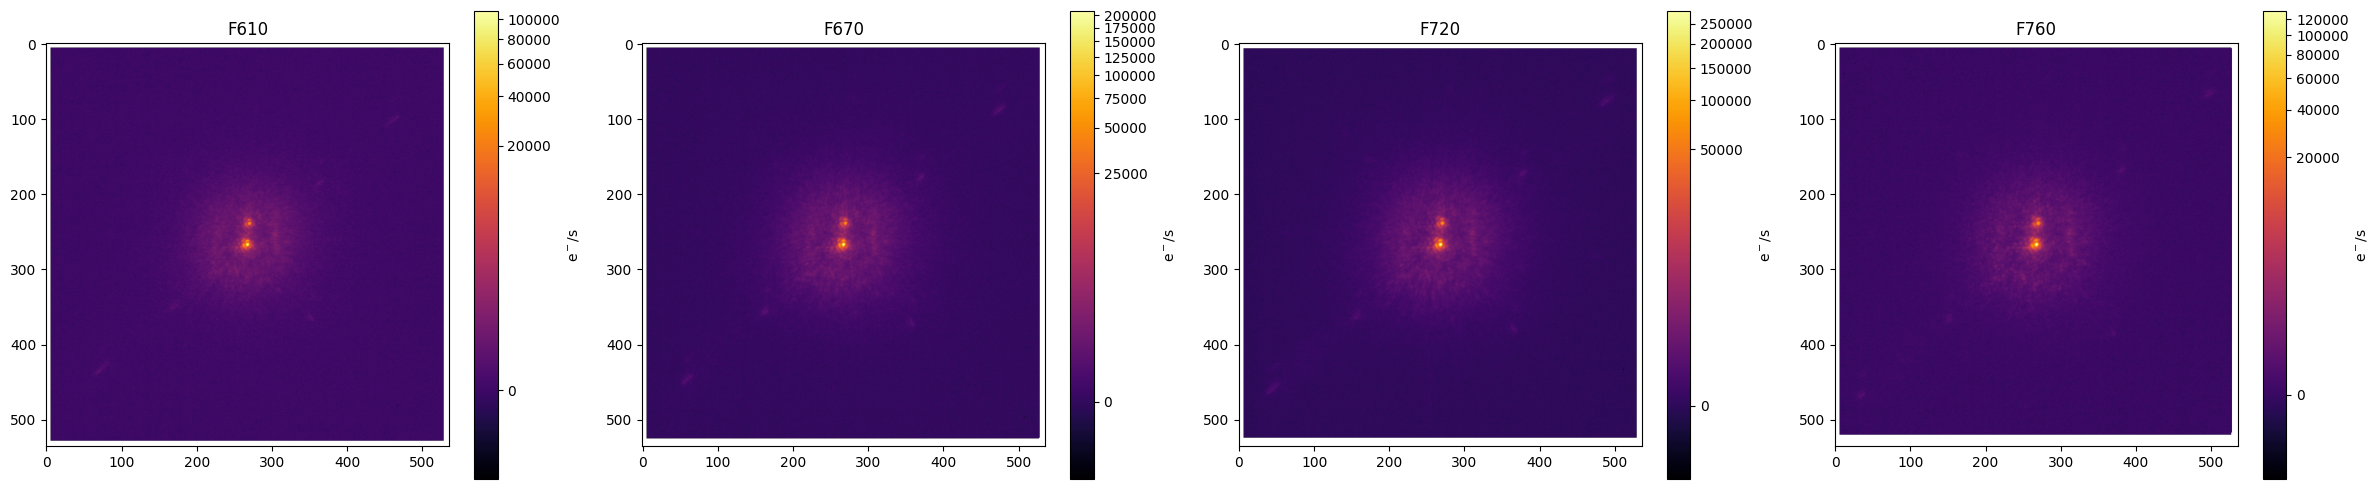

In [4]:
plt.figure(figsize=(24, 5))
%matplotlib inline
for i, img in enumerate(data):
    plt.subplot(1, 4, i+1)
    plt.imshow(img, cmap='inferno', norm=PowerNorm(0.2), origin='upper')
    plt.colorbar(label='e$^-$/s')
    plt.title(bands[i])

plt.tight_layout()

#### 1. Auto-correlation
Smooth and symmetric profiles with sharp peaks at stellar locations - great for fitting loc precisely.

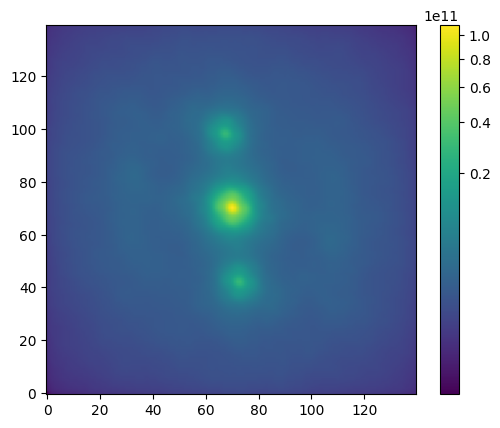

In [5]:
crp_sz = 140
shave_off = (data.shape[1]-crp_sz)//2
t = data[0][shave_off:-shave_off, shave_off:-shave_off]
plt.imshow(fftconvolve(t, t[::-1,::-1], mode='same'), cmap='viridis', norm=PowerNorm(0.3), origin='lower')
plt.colorbar()

In [6]:
def auto_corr(img: np.array, crp_sz: int=None, norm: bool=True) -> np.array:
    if crp_sz is not None:
        shave_off = (img.shape[0]-crp_sz)//2
        img = img[shave_off:-shave_off, shave_off:-shave_off]

    ac = fftconvolve(img, img[::-1, ::-1], mode='same')

    if norm:
        ac /= np.max(ac)

    return ac

#### 2. Find PSF locations
For both primary and companion. 

In [7]:
def gauss2d(px_coords: jnp.array, x0: float, y0: float, sig_x: float, sig_y: float, A: float=1., B: float=0.) -> jnp.array:
    """
        Generates a 2D Gaussian array defined on pixel grid.

        Parameters
        ----------
        px_coords : Array
            Array of shape (2, N, N) describing x,y pixel coordinates respectvely.
        x0, y0 : float
            Center of the Gaussian in units of coordinates
        sig_x, sig_y : float
            Standard deviations of the Gaussian along x and y axes.
        A : float
            Amplitude of the Gaussian.
        B : float
            Z-offset of the Gaussian.
        
        Returns
        -------
        Array
            2D array of shape (N, N) describing Gaussian profile.
    """
    return A * jnp.exp(-((px_coords[0]-x0)**2/(2*sig_x**2) + (px_coords[1]-y0)**2/(2*sig_y**2))) + B

In [8]:
# Qaudratic loss fns great because we can solve with Newton method in single step
def MSE(img1: jnp.array, img2: jnp.array) -> float:
    """
        Computes Mean Squared Error between two images.

        Parameters

        img1, img2 : Array
            2D arrays of the same shape.

        Returns
        -------
        float
            Mean Squared Error between the two images.
    """
    return jnp.mean((img1 - img2)**2)

def loss_fn(p: jnp.array, data: jnp.array, px_coords: jnp.array) -> float:
    """
        Loss function to be minimized.

        Parameters
        ----------
        p : Array
            Array of shape (6,) containing Gaussian parameters:
            [x0, y0, sig_x, sig_y, A, B]
        data : Array
            2D array containing the data image.
        px_coords : Array
            Array of shape (2, N, N) describing x,y pixel coordinates respectvely.

        Returns
        -------
        float
            Computed loss value.
    """
    model = gauss2d(px_coords, p[0], p[1], p[2], p[3], p[4], p[5])
    return MSE(data, model)



In [9]:
def find_binary_peaks(img: np.array, threshold: float=0.5, prox_thresh: int=5, ref_loc: np.array=None):
    """
        Returns location of primary and companion peaks.

        Parameters
        ----------
        img : Array
            2D array representing the image.
        threshold : float
            Threshold value to consider a pixel as a peak.
        prox_thresh : int
            Minimum distance between peaks, pixels.
        ref_loc : Array
            Reference location of companion peak to pick.

        Returns
        -------
        (x0, y0), (x1, y1) : 
            x0,y0 location of primary peak (assumed to be brighter star), 
            x1,y1 location of companion peak.
            Returns None if less than two peaks are found.
    """
    peak_coords = feature.peak_local_max(img, threshold_abs=threshold, min_distance=prox_thresh, num_peaks=3) #max number of 3 peaks

    if len(peak_coords) < 2:
        return None
    elif ref_loc is not None:
        dists = [np.linalg.norm(coord - ref_loc) for coord in peak_coords]
        comp_idx = np.argmin(dists)
        max_order = np.argsort([img[tuple(coord)] for coord in peak_coords]) #sort peaks by brightness
        return tuple(peak_coords[max_order[-1]]), tuple(peak_coords[comp_idx])
    else:
        max_order = np.argsort([img[tuple(coord)] for coord in peak_coords]) #sort peaks by brightness
        return tuple(peak_coords[max_order[-1]]), tuple(peak_coords[max_order[-2]])

In [10]:
grad_fn = jit(grad(loss_fn, argnums=0))
hess_fn = jit(hessian(loss_fn, argnums=0)) # jit and gpu to run v fast

Create data saving directories

In [11]:
if not os.path.exists(os.getcwd()+"/data/fit_imgs"):
    os.makedirs(os.getcwd()+"/data/fit_imgs")

if not os.path.exists(os.getcwd()+"/data/fit_results"):
    os.makedirs(os.getcwd()+"/data/fit_results")

In [12]:
# header = ['U_CAMERA', 'FILT', 'PA', 'x_prim_px', 'x_prim_err', 'y_prim', 'y_prim_err','x_comp', 'x_comp_err', 'y_comp', 'y_comp_err']
# intermediate data dict
header = ['file', 'U_CAMERA', 'FILT', 'PA', 'x_prim_px', 'y_prim_px', 'x_comp_px', 'y_comp_px']

data_dict = dict.fromkeys(header)
for key in data_dict:
    data_dict[key] = [] 

Loop through data

1/316 processed
2/316 processed
3/316 processed
4/316 processed
5/316 processed
6/316 processed
7/316 processed
8/316 processed
9/316 processed
10/316 processed
11/316 processed
12/316 processed
13/316 processed
14/316 processed
15/316 processed
16/316 processed
17/316 processed
18/316 processed
19/316 processed
20/316 processed
21/316 processed
22/316 processed
23/316 processed
24/316 processed
25/316 processed
26/316 processed
27/316 processed
28/316 processed
29/316 processed
30/316 processed
31/316 processed
32/316 processed
33/316 processed
34/316 processed
35/316 processed
36/316 processed
37/316 processed
38/316 processed
39/316 processed
40/316 processed
41/316 processed
42/316 processed
43/316 processed
44/316 processed
45/316 processed
46/316 processed
47/316 processed
48/316 processed
49/316 processed
50/316 processed
51/316 processed
52/316 processed
53/316 processed
54/316 processed
55/316 processed
56/316 processed
57/316 processed
58/316 processed
59/316 processed
60/316

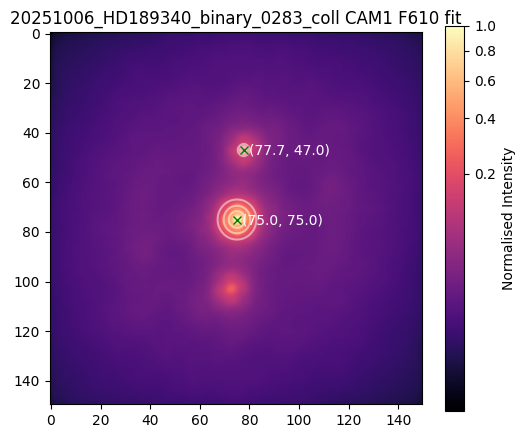

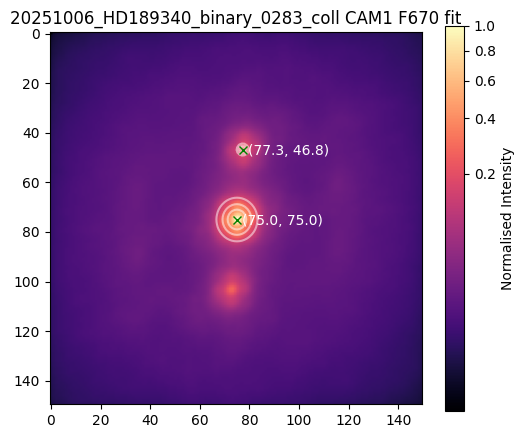

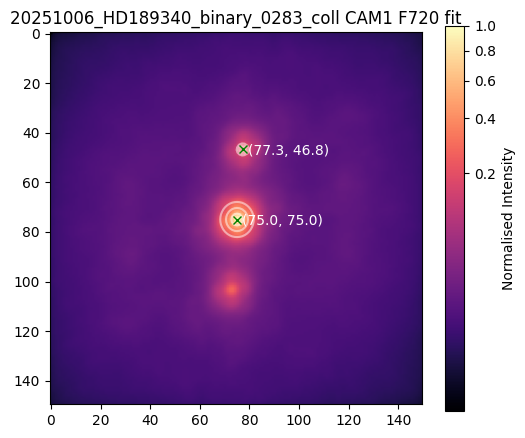

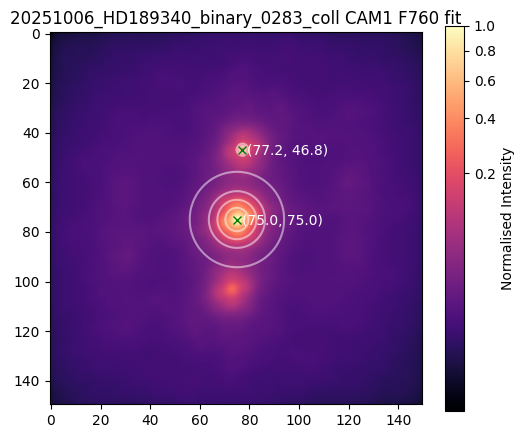

In [13]:
crp_sz, airy_hlf_px = 150, 15 #px, px 
coords= jnp.asarray(jnp.meshgrid(jnp.arange(crp_sz), jnp.arange(crp_sz)), dtype=float) # (2, crp_sz, crp_sz)

# ref loc of companion star in px
hdul = fits.open(data_dir+os.listdir(data_dir)[0])
eg_im = hdul[0].data[0]
shave_off = (eg_im.shape[0]-crp_sz)//2
eg_im = eg_im[shave_off:-shave_off, shave_off:-shave_off]

prim, compan_coord = find_binary_peaks(eg_im, threshold=25000)

savefitfig = True
for j, fname in enumerate(os.listdir(data_dir)):
    hdul = fits.open(data_dir+fname)
    cam, pa = hdul[0].header['U_CAMERA'], hdul[0].header['PA']

    for i, band_str in enumerate(bands):
        data = hdul[0].data[i]
        ac_img = auto_corr(data, crp_sz=crp_sz, norm=True)
        peak_coords = find_binary_peaks(ac_img, threshold=0.2, prox_thresh=airy_hlf_px, ref_loc=compan_coord)

        if peak_coords is not None:
            opt_p = [] # optimised parameter arrays for primary and companion respectively
            for row,col in peak_coords:
                crp_img = ac_img[row-airy_hlf_px:row+airy_hlf_px, col-airy_hlf_px:col+airy_hlf_px]
                crp_coords = coords[:,row-airy_hlf_px:row+airy_hlf_px, col-airy_hlf_px:col+airy_hlf_px]

                p0 = jnp.array([col, row, 2., 2., 1., 0.], dtype=float) # [x0, y0, sig_x, sig_y, A, B]
                p = p0 - jnp.linalg.solve(hess_fn(p0, crp_img, crp_coords), grad_fn(p0, crp_img, crp_coords)) # single-step newton update

                opt_p.append(p)

            data_dict['file'].append(fname)
            data_dict['U_CAMERA'].append(cam)
            data_dict['FILT'].append(band_str)
            data_dict['PA'].append(pa)
            data_dict['x_prim_px'].append(opt_p[0][0])
            data_dict['y_prim_px'].append(opt_p[0][1])
            data_dict['x_comp_px'].append(opt_p[1][0])
            data_dict['y_comp_px'].append(opt_p[1][1])

            if savefitfig:
                plt.figure(figsize=(6,5))
                plt.imshow(ac_img, cmap='magma', norm=PowerNorm(0.3), origin='upper')
                plt.colorbar(label='Normalised Intensity')
                for p in opt_p:
                    x0, y0 = p[0], p[1]
                    plt.contour(gauss2d(coords, x0=x0, y0=y0, sig_x=p[2], sig_y=p[3], A=p[4], B=p[5]), levels=3, colors='w', alpha=0.5)
                    plt.plot(x0, y0, 'gx')
                    plt.text(x0+2, y0+2, f"({x0:.1f}, {y0:.1f})", color='w')

                plt.title(f"{fname[:-5]} CAM{cam} {band_str} fit")
                plt.savefig(os.getcwd()+f"/data/fit_imgs/{fname[:-5]}_CAM{cam}_{band_str}_fit.png", dpi=150)
                if j != 0:
                    plt.close()
                    # show 1 fig per band
    print("{}/{} processed".format(j+1, len(os.listdir(data_dir))))


path =os.getcwd()+"/data/fit_results/binary_fit_results.pkl"

with open(path, "wb") as f:
    pickle.dump(data_dict, f)


#### 3. Stats

In [14]:
header = ['file', 'mjd', 'U_CAMERA', 'FILT', 'PA','sep_px', 'theta_deg']
bin_params_dict = dict.fromkeys(header)
for key in bin_params_dict:
    bin_params_dict[key] = [] 

In [18]:
fits_dict = pickle.load(open(os.getcwd()+"/data/fit_results/binary_fit_results.pkl", 'rb')) 
for frame_i in range(len(fits_dict['U_CAMERA'])):
    p1, p2 = jnp.asarray([jnp.array(fits_dict['x_prim_px'][frame_i]), jnp.array(fits_dict['y_prim_px'][frame_i])]), \
        jnp.asarray([jnp.array(fits_dict['x_comp_px'][frame_i]), jnp.array(fits_dict['y_comp_px'][frame_i])])

    sep = jnp.linalg.norm(p2 - p1)
    theta = jnp.degrees(jnp.arctan2(p2[0]-p1[0], p2[1]-p1[1])) % 360

    bin_params_dict['file'].append(fits_dict['file'][frame_i])
    bin_params_dict['mjd'].append(fits.open(data_dir+fits_dict['file'][frame_i])[0].header['MJD-STR'])
    bin_params_dict['U_CAMERA'].append(fits_dict['U_CAMERA'][frame_i])
    bin_params_dict['FILT'].append(fits_dict['FILT'][frame_i])
    bin_params_dict['PA'].append(fits_dict['PA'][frame_i])
    bin_params_dict['sep_px'].append(sep)
    bin_params_dict['theta_deg'].append(theta)

bin_params_df = pd.DataFrame(bin_params_dict)
bin_params_df.sort_values(by='mjd', inplace=True)


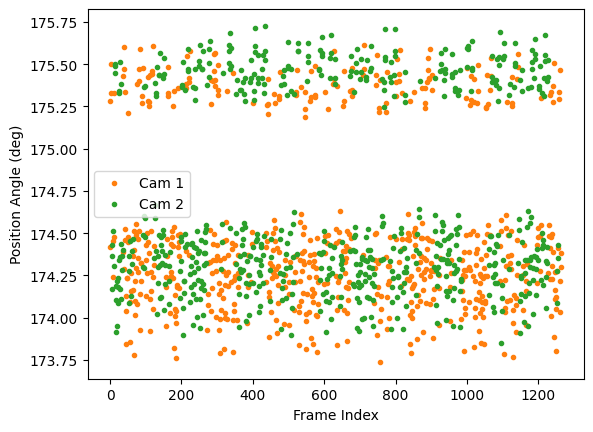

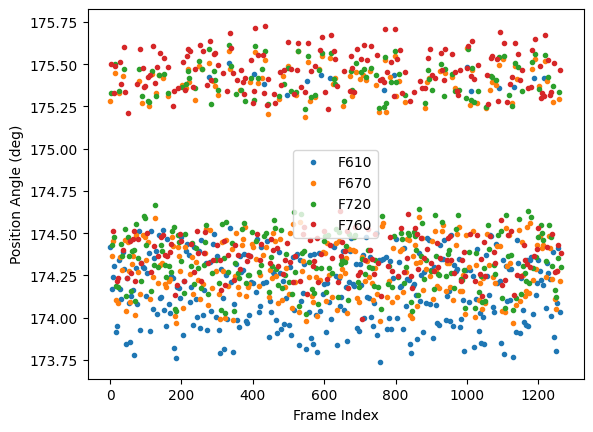

In [19]:
plt.figure()
for cam_i in [1,2]:
    sub_df  = bin_params_df[bin_params_df['U_CAMERA']==cam_i]
    idxs = bin_params_df.index[bin_params_df['U_CAMERA']==cam_i]
    plt.plot(idxs, sub_df['theta_deg'], '.', c="C{}".format(cam_i), label='Cam {}'.format(cam_i))

plt.xlabel('Frame Index')
plt.ylabel('Position Angle (deg)')
plt.legend()

plt.figure()
for i in range(len(bands)):
    sub_df  = bin_params_df[bin_params_df['FILT']==bands[i]]
    idxs = bin_params_df.index[bin_params_df['FILT']==bands[i]]
    plt.plot(idxs,sub_df['theta_deg'], '.', c='C{}'.format(bands.index(bands[i])), label=bands[i])

plt.xlabel('Frame Index')
plt.ylabel('Position Angle (deg)')
plt.legend()

In [20]:
def bootstrap(data: np.array):
    """
        For data cube of shape (n_frames,)
        randomly sample (with replacement) n_frames rows.

        Returns the mean over n_frames samples.
    """
    randsamp_indx = np.random.choice(np.arange(data.shape[0]), data.shape[0], replace=True) # uniform draw with replacement
    randsamp = data[randsamp_indx]

    return np.mean(randsamp, axis=0) 

In [22]:
mean_params_dict = {}
for cam in [1,2]:
    for filt in bands:
        sub_df = bin_params_df[(bin_params_df['U_CAMERA']==cam) & (bin_params_df['FILT']==filt)]
        seps, thetas = sub_df['sep_px'].to_numpy(), sub_df['theta_deg'].to_numpy()
        PAs = sub_df['PA'].to_numpy()
        theta_derot = thetas - PAs # de-rotate theta values given PA

        n_bootstrap = 1000
        sep_samps, theta_samps = [], []
        for _ in range(n_bootstrap):
            samp_sep = bootstrap(seps)
            samp_theta = bootstrap(theta_derot)

            sep_samps.append(samp_sep)
            theta_samps.append(samp_theta)

        sep_mean, sep_std = np.mean(seps), np.std(np.asarray(sep_samps))
        theta_mean, theta_std = np.mean(theta_derot), np.std(np.asarray(theta_samps))

        mean_params_dict[(cam, filt)] = {'sep_mean_px': sep_mean, 'sep_std_px': sep_std,
                                         'theta_mean_deg': theta_mean, 'theta_std_deg': theta_std}
        
        print(cam, filt)


1 F610
1 F670
1 F720
1 F760
2 F610
2 F670
2 F720
2 F760


#### 4. Measure Plate Scale!

Using known emphem data

In [23]:
# get position and sep for obs time (UT)
hdul = fits.open(data_dir+bin_params_df['file'].values[0])
start_date_ut = toYearFraction(dt.fromisoformat(hdul[0].header['DATE']))
print("Start {}".format(dt.fromisoformat(hdul[0].header['DATE'])))
# start_date_ut = toYearFraction(dt.utcnow())

# insiginificant change in sep and binary PA over observation period
hdul = fits.open(data_dir+bin_params_df['file'].values[-1])
end_date_ut = toYearFraction(dt.fromisoformat(hdul[0].header['DATE']))
print("End {}".format(dt.fromisoformat(hdul[0].header['DATE'])))


#  WDS 19598-0957 (TODO automate from table)
t0 =  2026.623 # periastron date in decimal year (TTTTT.TTTTTT) 
t0_err = 0.001 #toYearFraction(julian.from_jd(0.001,"mjd"))

T = 4.8705 # orbital period in decimal year (ppppp.ppppp)
T_err = 0.003

smaj = 0.1518 # semi-major axis in arcsec (aaa.aaaaa)
smaj_err = 0.0004

ecc = 0.6015 # eccentricity (e.eeeeee)
ecc_err = 0.0035      

inc = 17.32 # inclination in degrees (iii.iiii in 6th cat) # vs 46.38
inc_err = 1.5

small_om = 132.15 # argument of periastron in degrees (ooo.oooo in 6th cat) # vs 24.61
small_om_err = 8.00    

big_om =  154.19 # position angle of the ascending node in degrees (OOO.OOOO in 6th cat) vs 17.81
big_om_err = 8.00

sep, pa = binary_ephem(
    current_date=start_date_ut,
    t0=t0,
    T=T,
    smaj=smaj,
    ecc=ecc,
    inc=inc,
    small_om=small_om,
    big_om=big_om,
    display=display,
    t0_err=t0_err,
    T_err=T_err,
    smaj_err=smaj_err,
    ecc_err=ecc_err,
    inc_err=inc_err,
    small_om_err=small_om_err,
    big_om_err=big_om_err,
    nsamp = 100,
)

sep_mean, pa_mean = sep.mean(), pa.mean() # (mas)
sep_std, pa_std = sep.std(), pa.std() 


Start 2025-10-05 08:03:58
End 2025-10-05 08:10:31
Binary separation: 164.40238 +/- 0.55885 mas
Binary Position Angle: 153.31528 +/- 10.46117 degrees
Binary separation: 164.40238 +/- 0.55885 mas
Binary Position Angle: 153.31528 +/- 10.46117 degrees


In [24]:
for cam in [1,2]:
    for filt in bands:
        print(f"Camera {cam}, Filter {filt}:")
        print("Measured Sep (px): {:.2f} ± {:.2f} px | Predicted Sep: {:.2f} ± {:.2f} mas".format(mean_params_dict[(cam, filt)]['sep_mean_px'], mean_params_dict[(cam, filt)]['sep_std_px'],\
                                                                                                  sep_mean, sep_std))
        print("Measured PA: {:.2f} ± {:.2f} deg | Predicted PA: {:.2f} ± {:.2f} deg ".format(mean_params_dict[(cam, filt)]['theta_mean_deg'], mean_params_dict[(cam, filt)]['theta_std_deg'],\
                                                                                             pa_mean, pa_std))

        ps = sep_mean/mean_params_dict[(cam, filt)]['sep_mean_px']
        err_ps = ps*(mean_params_dict[(cam, filt)]['sep_std_px']/mean_params_dict[(cam, filt)]['sep_mean_px'] + sep_std/sep_mean)
        print("Plate scale {:.2f} ± {:.2f} mas/px".format(ps, err_ps))
        print()

Camera 1, Filter F610:
Measured Sep (px): 28.13 ± 0.00 px | Predicted Sep: 164.26 ± 0.56 mas
Measured PA: 120.88 ± 0.01 deg | Predicted PA: 153.57 ± 10.46 deg 
Plate scale 5.84 ± 0.02 mas/px

Camera 1, Filter F670:
Measured Sep (px): 28.31 ± 0.00 px | Predicted Sep: 164.26 ± 0.56 mas
Measured PA: 121.26 ± 0.02 deg | Predicted PA: 153.57 ± 10.46 deg 
Plate scale 5.80 ± 0.02 mas/px

Camera 1, Filter F720:
Measured Sep (px): 28.33 ± 0.00 px | Predicted Sep: 164.26 ± 0.56 mas
Measured PA: 121.34 ± 0.02 deg | Predicted PA: 153.57 ± 10.46 deg 
Plate scale 5.80 ± 0.02 mas/px

Camera 1, Filter F760:
Measured Sep (px): 28.26 ± 0.00 px | Predicted Sep: 164.26 ± 0.56 mas
Measured PA: 121.58 ± 0.02 deg | Predicted PA: 153.57 ± 10.46 deg 
Plate scale 5.81 ± 0.02 mas/px

Camera 2, Filter F610:
Measured Sep (px): 28.36 ± 0.00 px | Predicted Sep: 164.26 ± 0.56 mas
Measured PA: 121.07 ± 0.02 deg | Predicted PA: 153.57 ± 10.46 deg 
Plate scale 5.79 ± 0.02 mas/px

Camera 2, Filter F670:
Measured Sep (px)